# CLS-01: Telco Customer Churn — Exploratory Data Analysis & Data Profiling
**Project:** Data Mining 3-Task Production System (Classification Task 4: Customer Churn Prediction)  
**Owner:** Febronia (Classification Data Engineer)  
**Dataset:** IBM Telco Customer Churn (`datasets/classification/raw_telco_churn.csv`)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("../results/classification", exist_ok=True)

## 1. Load Dataset & Inspect Dimensions / Schema

In [2]:
DATA_PATH = "../datasets/classification/raw_telco_churn.csv"
df = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df.shape} (Rows: {df.shape[0]}, Columns: {df.shape[1]})")
assert df.shape == (7043, 21), f"Expected (7043, 21), got {df.shape}"
display(df.head())
print("\n--- DataFrame Info ---")
df.info()

Dataset Shape: (7043, 21) (Rows: 7043, Columns: 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-nu

## 2. Missing Values & Hidden Whitespace Profiling (`TotalCharges`)

In [3]:
print("Standard NaN counts per column before TotalCharges fix:")
print(df.isna().sum()[df.isna().sum() > 0])

# Detect hidden whitespace strings in TotalCharges
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print(f"Hidden whitespace rows in TotalCharges: {blank_mask.sum()}")
display(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# Convert whitespace to NaN and cast to float64
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", np.nan))
print(f"Missing in TotalCharges after conversion: {df['TotalCharges'].isna().sum()}")
print(f"TotalCharges dtype: {df['TotalCharges'].dtype}")

Standard NaN counts per column before TotalCharges fix:


Series([], dtype: int64)
Hidden whitespace rows in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Missing in TotalCharges after conversion: 11
TotalCharges dtype: float64


## 3. Duplicate Records & Target Class Imbalance Analysis

Exact duplicate rows (with customerID): 0
Feature-identical rows (excluding customerID): 22

Target Class Distribution (Churn):


,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


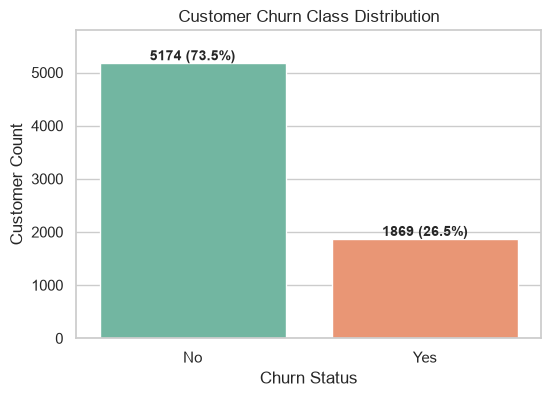

In [4]:
print(f"Exact duplicate rows (with customerID): {df.duplicated().sum()}")
print(f"Feature-identical rows (excluding customerID): {df.drop(columns=['customerID']).duplicated().sum()}")

target_counts = df["Churn"].value_counts()
target_pct = df["Churn"].value_counts(normalize=True) * 100
imbalance_df = pd.DataFrame({"Count": target_counts, "Percentage (%)": target_pct.round(2)})
print("\nTarget Class Distribution (Churn):")
display(imbalance_df)

# Save mandatory churn distribution plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Churn", data=df, hue="Churn", palette="Set2", legend=False)
for p in ax.patches:
    count = int(p.get_height())
    pct = 100.0 * count / len(df)
    ax.annotate(f"{count} ({pct:.1f}%)", (p.get_x() + p.get_width() / 2.0, count),
                ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Customer Count")
plt.ylim(0, df["Churn"].value_counts().max() * 1.12)
plt.savefig("../results/classification/churn_distribution.png", bbox_inches="tight", dpi=150)
plt.show()

## 4. Numerical Statistics & Outlier Detection (IQR Rule)

In [5]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[num_cols].describe().T)

outlier_rows = []
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({"Feature": col, "Q1": round(q1, 2), "Q3": round(q3, 2),
                         "IQR": round(iqr, 2), "Lower": round(lower, 2),
                         "Upper": round(upper, 2), "Outliers": n_out})
display(pd.DataFrame(outlier_rows))

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


,Feature,Q1,Q3,IQR,Lower,Upper,Outliers
0,tenure,9.00,55.00,46.00,-60.00,124.00,0
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0
2,TotalCharges,401.45,3794.74,3393.29,-4688.48,8884.67,0


## 5. Relationships & Correlations (`Contract`, `tenure`, `MonthlyCharges`, `InternetService` vs. `Churn`)

Churn Rate (%) by Contract Type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


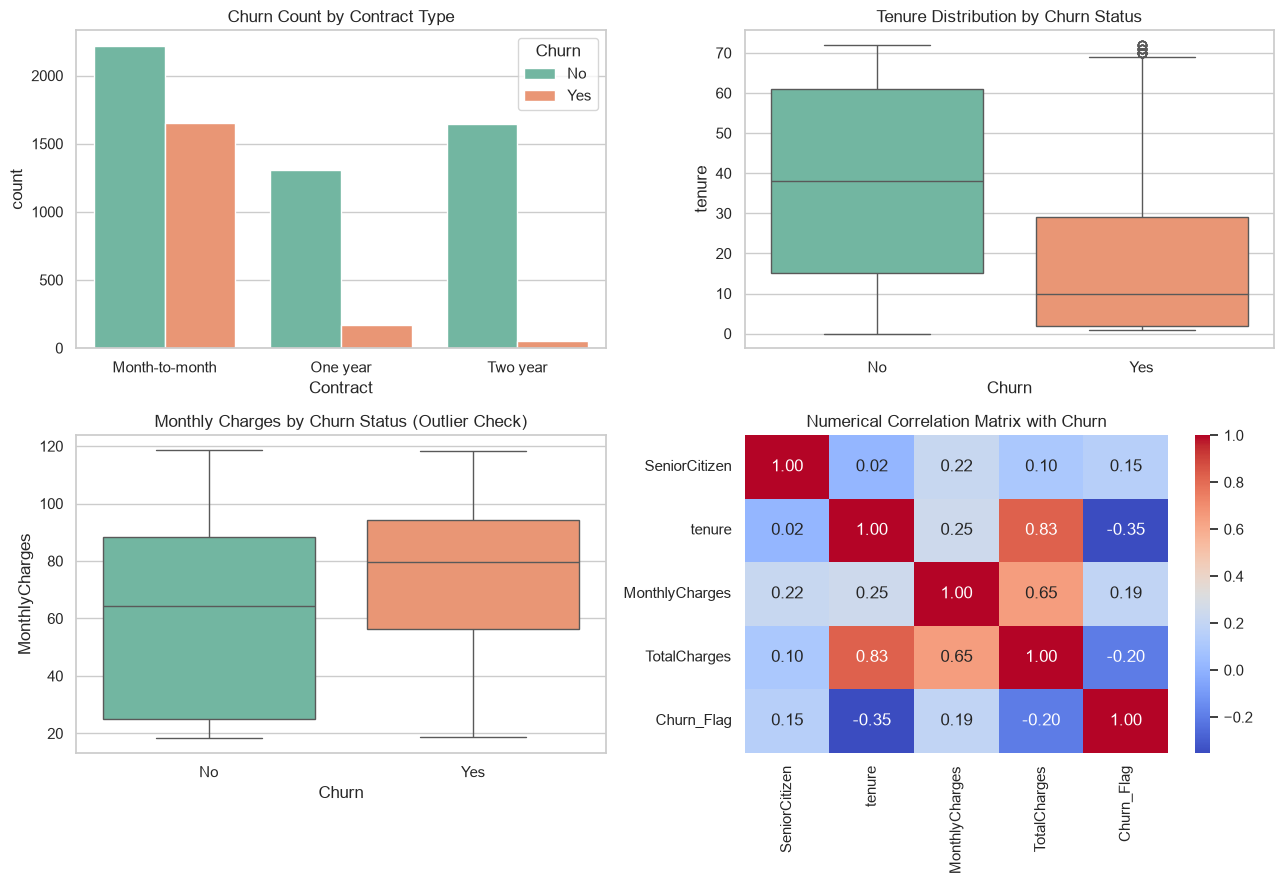

In [6]:
# Churn rate by Contract type
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print("Churn Rate (%) by Contract Type:")
display(contract_churn.round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Contract vs Churn
sns.countplot(data=df, x="Contract", hue="Churn", palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("Churn Count by Contract Type")

# 2. Tenure vs Churn
sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", palette="Set2", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Tenure Distribution by Churn Status")

# 3. MonthlyCharges vs Churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette="Set2", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Monthly Charges by Churn Status (Outlier Check)")

# 4. Correlation Heatmap
corr_df = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].copy()
corr_df["Churn_Flag"] = df["Churn"].map({"Yes": 1, "No": 0})
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Numerical Correlation Matrix with Churn")

plt.tight_layout()
plt.savefig("../results/classification/eda_relationships.png", bbox_inches="tight", dpi=150)
plt.show()

## 6. Key EDA Findings & Preprocessing Action Plan
1. **Dataset Dimensions:** 7,043 rows × 21 columns (`customerID` + 19 features + `Churn`).
2. **Hidden Whitespace Bug:** 11 rows with `tenure == 0` contain `' '` in `TotalCharges`; converted to `np.nan` -> `float64` and handled via median imputation fit strictly on `X_train`.
3. **Class Imbalance:** ~73.5% `No` vs ~26.5% `Yes` -> requires **Stratified Split** + **SMOTE** on `X_train` only.
4. **Outliers:** IQR check confirms 0 erroneous outliers in `tenure`, `MonthlyCharges`, or `TotalCharges`.
5. **Strongest Drivers:** Month-to-month contracts (~42.7% churn), shorter tenure, and higher monthly charges strongly correlate with customer churn.